In [98]:
import numpy as np
from tyssue.config.geometry import flat_sheet
from tyssue import Sheet, Monolayer, config, SheetGeometry
import pandas as pd

def one_face_sheet_array():

    Nc = 1
    
    points = np.array(

        [
            [3,9],
            [6,12],
            [10,10],
            [10,6],
            [6.05, 2.2],
            [2.5, 6],
        
        ] )


    edges = np.array(

        [
            [0, 1],
            [1, 2],
            [2, 3],
            [3, 4], 
            [4, 5], 
            [5, 0],

        ] )

    Nv, Ne = len(points), len(edges)
    return points, edges, (Nc, Nv, Ne)

In [100]:
from tyssue.generation.utils import make_df

def one_face_sheet(zaxis = False):

    points, _, (Nc, Nv, Ne) = one_face_sheet_array()

    if zaxis:
        coords = ['x', 'y', 'z']

    else:

        coords = ['x', 'y']


    face_idx = pd.Index([0], name='face')
    vert_idx = pd.Index(range(Nv), name="vert")


    _edge_e_idx = np.array(
        [
            [0, 1, 0],
            [1, 2, 0],
            [2, 3, 0],
            [3, 4, 0],
            [4, 5, 0],
            [5, 0, 0],
            
            
        ]
    )

    edge_idx = pd.Index(range(_edge_e_idx.shape[0]), name="edge")

    specifications = flat_sheet()

    
    ## Faces DataFrame
    face_df = make_df(index=face_idx, spec=specifications["face"])
    
    ## Junction vertices and edges DataFrames
    vert_df = make_df(index=vert_idx, spec=specifications["vert"])
    edge_df = make_df(index=edge_idx, spec=specifications["edge"])


    # Junction vertices and edge dataframe
    edge_df["srce"] = _edge_e_idx[:, 0]
    edge_df["trgt"] = _edge_e_idx[:, 1]
    edge_df["face"] = _edge_e_idx[:, 2]


    vert_df.loc[:, coords[:2]] = points
    if zaxis:
        vert_df.loc[:, coords[2:]] = 0.0


    

    datasets = {"face": face_df, "vert": vert_df, "edge": edge_df}
    return datasets, specifications

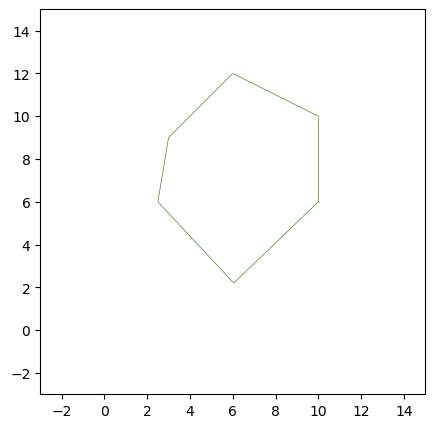

In [102]:
from tyssue.draw import sheet_view 



sheet = Sheet('1f', *one_face_sheet())



geom = SheetGeometry

geom.update_all(sheet)

fig, ax = sheet_view(sheet)

ax.set_xlim(-3, 15)
ax.set_ylim(-3, 15)
fig.set_size_inches(5, 5)

Vertices: 6
Edges: 6
Cells (faces): 1


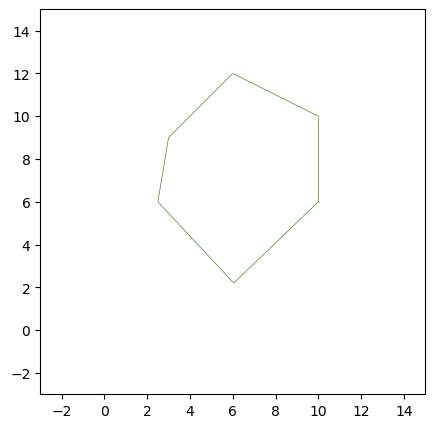

In [104]:
print("Vertices:", len(sheet.vert_df))
print("Edges:", len(sheet.edge_df))
print("Cells (faces):", len(sheet.face_df))



# Annotate 

# for face_id, face in sheet.face_df.iterrows():
#     ax.annotate(
#         f"F{face_id}", (face["x"], face["y"]),
#         color="green", ha="center", va="center",
#         bbox=dict(boxstyle="round,pad=0.15", fc="white", alpha=0.8, ec="none"),
#     )


# for vertex_id, vertex in sheet.vert_df.iterrows():
#     ax.annotate(
#         f"V{vertex_id}", (vertex["x"], vertex["y"]),
#         xytext=(4, 4), textcoords="offset points",
#         color="red", fontsize=8,
#     )




fig, ax = sheet_view(sheet)

ax.set_xlim(-3, 15)
ax.set_ylim(-3, 15)
geom.update_all(sheet)
fig.set_size_inches(5, 5)

In [106]:
print(sheet.vert_df[["x", "y"]]);
print(sheet.face_df[["area", "num_sides"]])

          x     y
vert             
0      3.00   9.0
1      6.00  12.0
2     10.00  10.0
3     10.00   6.0
4      6.05   2.2
5      2.50   6.0
      area  num_sides
face                 
0     48.5          6


In [108]:
sheet.face_df
sheet.edge_df

,srce,trgt,face,dx,dy,dz,nx,ny,nz,sx,...,length,is_active,ux,uy,uz,rx,ry,rz,sub_area,sub_vol
edge,,,,,,,,,,,,,,,,,,,,,
0,0,1,0,3.00,3.0,0.0,0.0,0.0,-14.175000,3.00,...,4.242641,1,0.707107,0.707107,0.0,-3.258333,1.466667,0.0,7.087500,-28.350000
1,1,2,0,4.00,-2.0,0.0,0.0,0.0,-17.350000,6.00,...,4.472136,1,0.894427,-0.447214,0.0,-0.258333,4.466667,0.0,8.675000,-34.700000
2,2,3,0,0.00,-4.0,0.0,0.0,0.0,-14.966667,10.00,...,4.000000,1,0.000000,-1.000000,0.0,3.741667,2.466667,0.0,7.483333,-29.933333
3,3,4,0,-3.95,-3.8,0.0,0.0,-0.0,-20.275000,10.00,...,5.481104,1,-0.720658,-0.693291,0.0,3.741667,-1.533333,0.0,10.137500,-40.550000
4,4,5,0,-3.55,3.8,0.0,-0.0,0.0,-19.725000,6.05,...,5.200240,1,-0.682661,0.730735,0.0,-0.208333,-5.333333,0.0,9.862500,-39.450000
5,5,0,0,0.50,3.0,0.0,-0.0,0.0,-10.508333,2.50,...,3.041381,1,0.164399,0.986394,0.0,-3.758333,-1.533333,0.0,5.254167,-21.016667


In [110]:
#### Area and perimeter calculation ####

#verify if it is using the shoelace formula to calculate the area of the irregular polygon
def hexagon_area(points):
    x = points[:, 0]
    y = points[:, 1]

    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


def hexagon_perimeter(points):

    x = points[:, 0]
    y = points[:, 1]

    # dx = np.roll(x, -1) - x
    # dy = np.roll(y, -1) - y

    # edge_lengths = np.sqrt(dx**2 + dy**2)

    # return np.sum(edge_lengths)
    
    
    
    # Euler distance #
    return np.sum(np.sqrt((np.roll(x, -1) - x)**2 + (np.roll(y, -1) - y)**2))  


In [112]:
points = np.array([
    [3,9],
    [6,12],
    [10,10],
    [10,6],
    [6.05, 2.2],
    [2.5, 6],
])

print(f"Area of the irregular hexagon: {hexagon_area(points)}")
print(f"Perimeter of the irregular hexagon: {hexagon_perimeter(points)}")

Area of the irregular hexagon: 48.5
Perimeter of the irregular hexagon: 26.437502189739543


In [114]:
valid_faces = sheet.face_df.index[sheet.face_df["area"] > 1e-12] # condition for a valid face

face_id = valid_faces[0]
# For this face, get its boundary's edge IDs and source vertex IDs
boundary = sheet.get_orbits("face", "srce").loc[face_id]

print("Face:", face_id) # print face id
print("Boundary edge IDs:", list(boundary.index)) # print edge id 
print("Boundary vertex IDs:", list(boundary.values)) # print vertex id

print(sheet.edge_df.loc[boundary.index, ["srce", "trgt", "length"]]) #calculating length by Euler distance           
print(sheet.vert_df.loc[boundary.values, ["x", "y"]])

Face: 0
Boundary edge IDs: [0, 1, 2, 3, 4, 5]
Boundary vertex IDs: [0, 1, 2, 3, 4, 5]
      srce  trgt    length
edge                      
0        0     1  4.242641
1        1     2  4.472136
2        2     3  4.000000
3        3     4  5.481104
4        4     5  5.200240
5        5     0  3.041381
          x     y
vert             
0      3.00   9.0
1      6.00  12.0
2     10.00  10.0
3     10.00   6.0
4      6.05   2.2
5      2.50   6.0


In [116]:
print(sheet.face_df.loc[face_id, ["area", "perimeter", "num_sides"]])
print(sheet.edge_df.loc[boundary.index, "length"].sum())

area         48.500000
perimeter    26.437502
num_sides     6.000000
Name: 0, dtype: float64
26.437502189739543


In [118]:
vertex_ids = boundary.values # boundary.values gives the vertex IDs, and ["x", "y"] selects their coordinate
coordinates = sheet.vert_df.loc[vertex_ids, ["x", "y"]] # .loc[rows, columns]
display(coordinates)

,x,y
vert,,
0,3.00,9.0
1,6.00,12.0
2,10.00,10.0
3,10.00,6.0
4,6.05,2.2
5,2.50,6.0


In [120]:
sheet.vert_df.loc[3, ["x", "y"]]

x    10.0
y     6.0
Name: 3, dtype: float64

Before:
area         48.500000
perimeter    26.437502
Name: 0, dtype: float64

After:
area         55.900000
perimeter    28.489082
Name: 0, dtype: float64


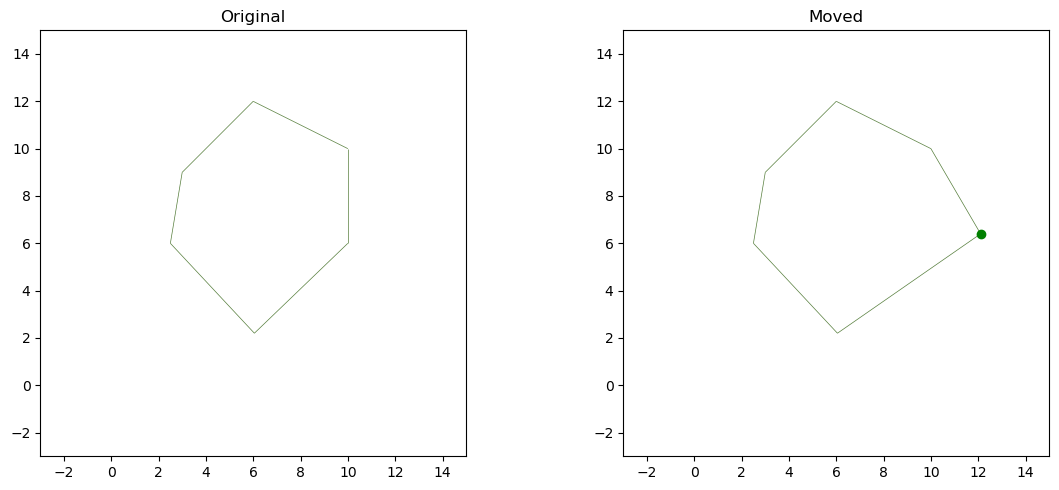

In [122]:
vertex_id = int(boundary.iloc[3])

sheet_moved = sheet.copy()
before = sheet.face_df.loc[face_id, ["area", "perimeter"]].copy()

# Move this vertex slightly to the right #
sheet_moved.vert_df.loc[vertex_id, "x"] += 2.1
sheet_moved.vert_df.loc[vertex_id, "y"] += 0.4


geom.update_all(sheet_moved)
after = sheet_moved.face_df.loc[face_id, ["area", "perimeter"]]

print("Before:")
print(before)
print("\nAfter:")
print(after)


# fig, ax = sheet_view(sheet_moved, mode="2D")
# ax.set_xlim(-3, 15)
# ax.set_ylim(-3, 15)
# geom.update_all(sheet)
# point = sheet_moved.vert_df.loc[vertex_id]
# ax.scatter(point["x"], point["y"], color="green", zorder=5)



# fig, ax = sheet_view(sheet, mode="2D")
# ax.set_xlim(-3, 15)
# ax.set_ylim(-3, 15)
# geom.update_all(sheet)


import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, s, title in zip(axes, [sheet, sheet_moved], ["Original", "Moved"]):
    geom.update_all(s)
    sheet_view(s, mode="2D", ax=ax)
    ax.set(xlim=(-3, 15), ylim=(-3, 15), title=title)

    if s is sheet_moved:
        point = s.vert_df.loc[vertex_id]
        ax.scatter(point["x"], point["y"], color="green", zorder=5)

plt.tight_layout()
plt.show()


In [124]:
comparison = (
    sheet.face_df[["area", "perimeter"]].add_suffix("_before")
    .join(sheet_moved.face_df[["area", "perimeter"]].add_suffix("_after"))
)

comparison["area_change"] = comparison["area_after"] - comparison["area_before"]
comparison["perimeter_change"] = comparison["perimeter_after"] - comparison["perimeter_before"]

print(comparison.round(3))

      area_before  perimeter_before  area_after  perimeter_after  area_change  \
face                                                                            
0            48.5            26.438        55.9           28.489          7.4   

      perimeter_change  
face                    
0                2.052  


In [142]:
from tyssue.dynamics import effectors, model_factory

model_sheet_new = sheet_moved.copy()
area_model = model_factory([effectors.FaceAreaElasticity])  # only energy from area is considered

model_sheet_new.update_specs(area_model.specs, reset=True)

# Set each cell's stiffness and preferred area
model_sheet_new.face_df["area_elasticity"] = 1.0
model_sheet_new.face_df["prefered_area"] = 80.0 


geom.update_all(model_sheet_new)

# print("TOTAL ENERGY ACROSS THE SHEET:", area_model.compute_energy(model_sheet))


# Calculate this term for the face we traced
area = model_sheet_new.face_df.loc[face_id, "area"]
stiffness = model_sheet_new.face_df.loc[face_id, "area_elasticity"]
target_area = model_sheet_new.face_df.loc[face_id, "prefered_area"]


cell_energy = 0.5 * stiffness * (area - target_area) ** 2  # main equation to calculate energy just by using face area elasticity
print("Face energy from area term:", cell_energy)

Reseting column is_alive of the face dataset with new specs
Reseting column area of the face dataset with new specs
Reseting column sub_area of the edge dataset with new specs


Face energy from area term: 290.40500000000003


In [144]:
grad_E = area_model.compute_gradient(model_sheet_new)

grad_E

,gx,gy,gz
srce,,,
0,125.32,-34.844583,0.0
1,40.97,-125.219583,0.0
2,-81.94,-139.679583,0.0
3,-159.06,54.325417,0.0
4,-24.10,165.185417,0.0
5,98.81,80.232917,0.0


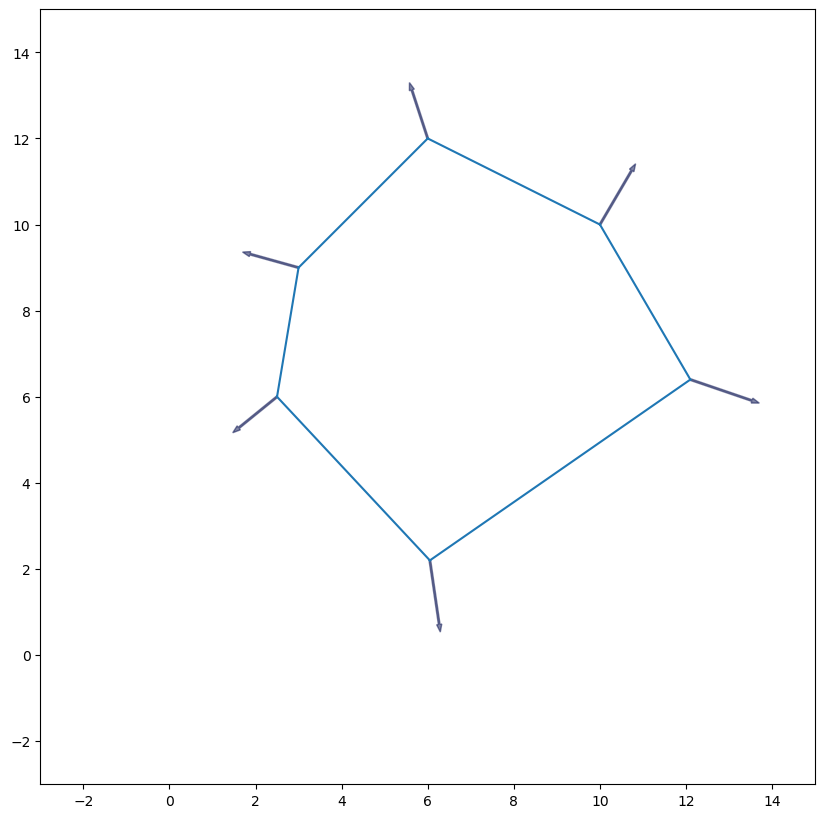

In [146]:
from tyssue.draw.plt_draw import plot_forces


fig, ax = plot_forces(model_sheet_new, geom, area_model, ['x', 'y'], scaling=0.009)
ax.set_xlim(-3, 15)
ax.set_ylim(-3, 15)

fig.set_size_inches(10, 12)

In [148]:

from tyssue.dynamics.planar_vertex_model import PlanarModel as smodel
from tyssue.solvers import QSSolver
from pprint import pprint

pprint(vars(model_sheet_new), sort_dicts=False, width=70)


{'_backups': deque([], maxlen=5),
 'identifier': '1f_copy_copy',
 'datasets': {'face':              x    y    z  num_sides  area  perimeter  is_alive  id  height  \
face                                                                         
0     6.608333  7.6  0.0          6  55.9  28.489082         1   0    -4.0   

      rho    vol  area_elasticity  prefered_area  
face                                              
0     0.0 -223.6              1.0           80.0  ,
              'vert':           x     y    z  is_active  rho  height  basal_shift       gx        gy
vert                                                                          
0      3.00   9.0  0.0          1  0.0    -4.0          4.0 -1.12788  0.313601
1      6.00  12.0  0.0          1  0.0    -4.0          4.0 -0.36873  1.126976
2     10.00  10.0  0.0          1  0.0    -4.0          4.0  0.73746  1.257116
3     12.10   6.4  0.0          1  0.0    -4.0          4.0  1.43154 -0.488929
4      6.05   2.2  0.0      

In [150]:
E_t = area_model.compute_energy(model_sheet_new)
print("Total energy: ", E_t)

Total energy:  290.40500000000003


In [152]:
area_model.compute_gradient(model_sheet_new).head()

,gx,gy,gz
srce,,,
0,125.32,-34.844583,0.0
1,40.97,-125.219583,0.0
2,-81.94,-139.679583,0.0
3,-159.06,54.325417,0.0
4,-24.10,165.185417,0.0


Successfull gradient descent?  True


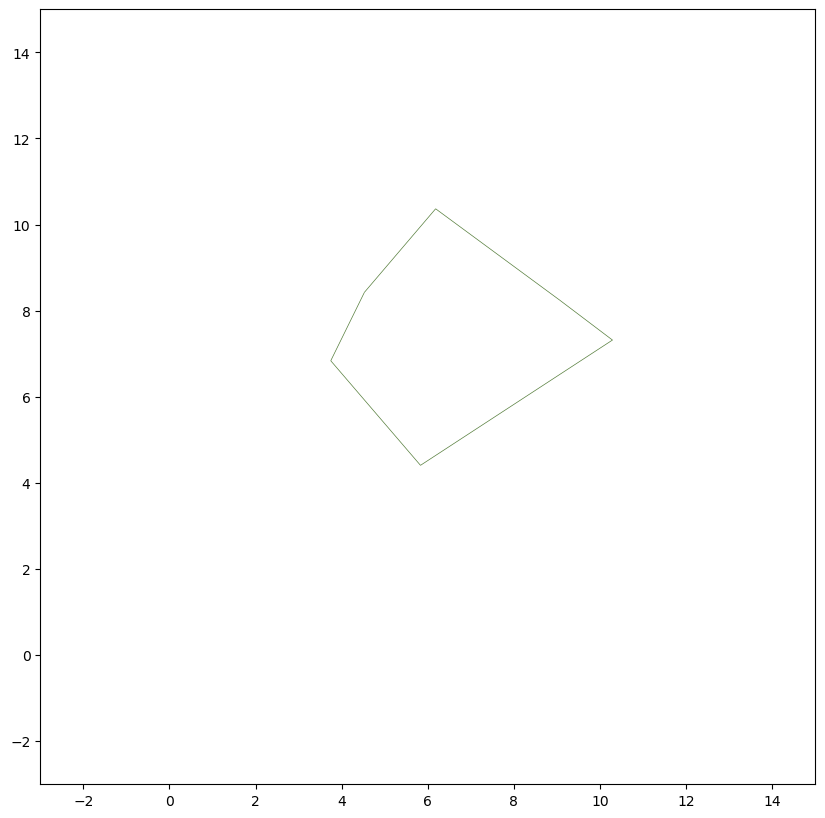

In [172]:
solver = QSSolver()
res = solver.find_energy_min(model_sheet_new, geom, area_model)

print("Successfull gradient descent? ", res['success'])
fig, ax = sheet_view(model_sheet_new)

fig.set_size_inches(10, 12)
ax.set_xlim(-3, 15)
ax.set_ylim(-3, 15)

ax.set_aspect('equal')

In [174]:
print('Total gradient error: ')
solver.check_grad(model_sheet_new, geom, area_model)

Total gradient error: 


0.00013695994121053649

In [176]:
app_grad = solver.approx_grad(model_sheet_new, geom, area_model)
app_grad = pd.DataFrame(app_grad.reshape((-1, 3)), columns=['gx', 'gy', 'gz'])

In [178]:
app_grad.head()


,gx,gy,gz
0,0.000067,-0.000046,0.0
1,-0.000003,-0.000086,0.0
2,-0.000058,-0.000078,0.0
3,-0.000073,0.000061,0.0
4,-0.000009,0.000124,0.0


In [180]:
pprint(vars(model_sheet_new), sort_dicts=False, width=70)

{'_backups': deque([], maxlen=5),
 'identifier': '1f_copy_copy',
 'datasets': {'face':              x    y             z  num_sides       area  perimeter  is_alive  \
face                                                                           
0     6.608333  7.6  5.300398e-09          6  19.999962  17.960444         1   

      id  height           rho        vol  area_elasticity  prefered_area  
face                                                                       
0      0    -4.0  5.300398e-09 -79.999849              1.0           20.0  ,
              'vert':               x          y             z  is_active           rho  height  \
vert                                                                        
0      4.530102   8.426735  1.488618e-13          1  1.488618e-13    -4.0   
1      6.183590  10.366443  2.727748e-14          1  2.727748e-14    -4.0   
2      9.065465   8.244556  5.740756e-14          1  5.740756e-14    -4.0   
3     10.290740   7.317448  1.873327

In [184]:
model_sheet_new.face_df.loc[0, "prefered_area"] = 70.0
pprint(vars(model_sheet_new), sort_dicts=False, width=70)

{'_backups': deque([], maxlen=5),
 'identifier': '1f_copy_copy',
 'datasets': {'face':              x    y             z  num_sides       area  perimeter  is_alive  \
face                                                                           
0     6.608333  7.6  5.300398e-09          6  19.999962  17.960444         1   

      id  height           rho        vol  area_elasticity  prefered_area  
face                                                                       
0      0    -4.0  5.300398e-09 -79.999849              1.0           70.0  ,
              'vert':               x          y             z  is_active           rho  height  \
vert                                                                        
0      4.530102   8.426735  1.488618e-13          1  1.488618e-13    -4.0   
1      6.183590  10.366443  2.727748e-14          1  2.727748e-14    -4.0   
2      9.065465   8.244556  5.740756e-14          1  5.740756e-14    -4.0   
3     10.290740   7.317448  1.873327

In [186]:
print('Total gradient error: ')
solver.check_grad(model_sheet_new, geom, area_model)

Total gradient error: 


181.1163068398995

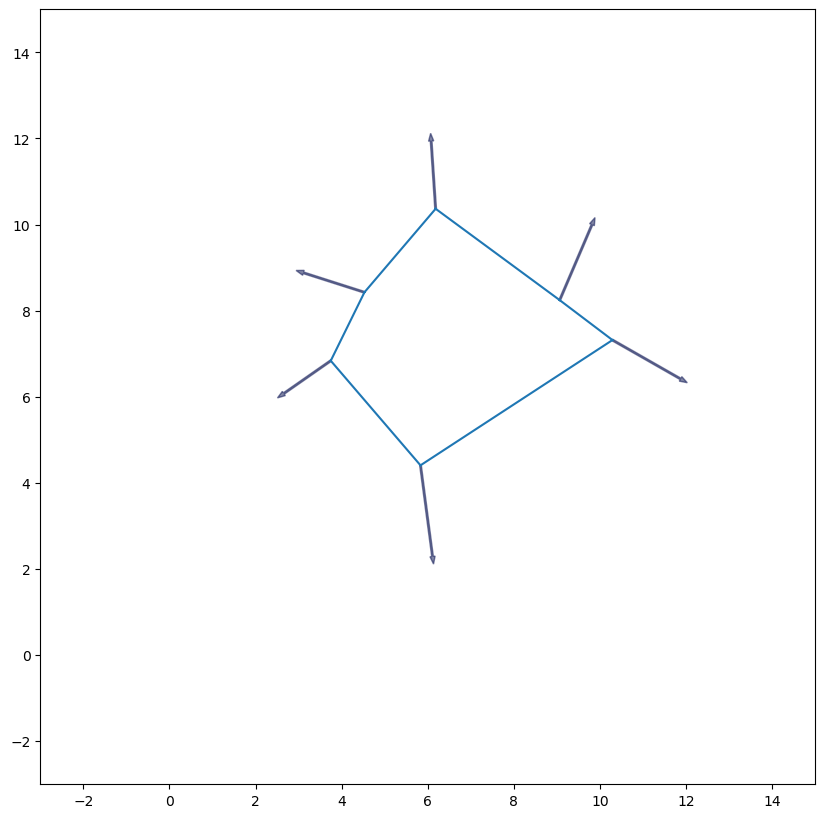

In [188]:
fig, ax = plot_forces(model_sheet_new, geom, area_model, ['x', 'y'], scaling=0.009)
ax.set_xlim(-3, 15)
ax.set_ylim(-3, 15)



fig.set_size_inches(10, 12)

In [190]:
app_grad = solver.approx_grad(model_sheet_new, geom, area_model)
app_grad = pd.DataFrame(app_grad.reshape((-1, 3)), columns=['gx', 'gy', 'gz'])

In [192]:
app_grad.head()


,gx,gy,gz
0,88.236440,-60.887482,0.0
1,-4.554522,-113.384194,0.0
2,-76.224972,-102.678760,0.0
3,-95.918259,80.836337,0.0
4,-12.011013,163.566469,0.0


In [194]:
E_t = area_model.compute_energy(model_sheet_new)
print("Total energy: ", E_t)

Total energy:  1250.0018905765558


Successfull gradient descent?  True


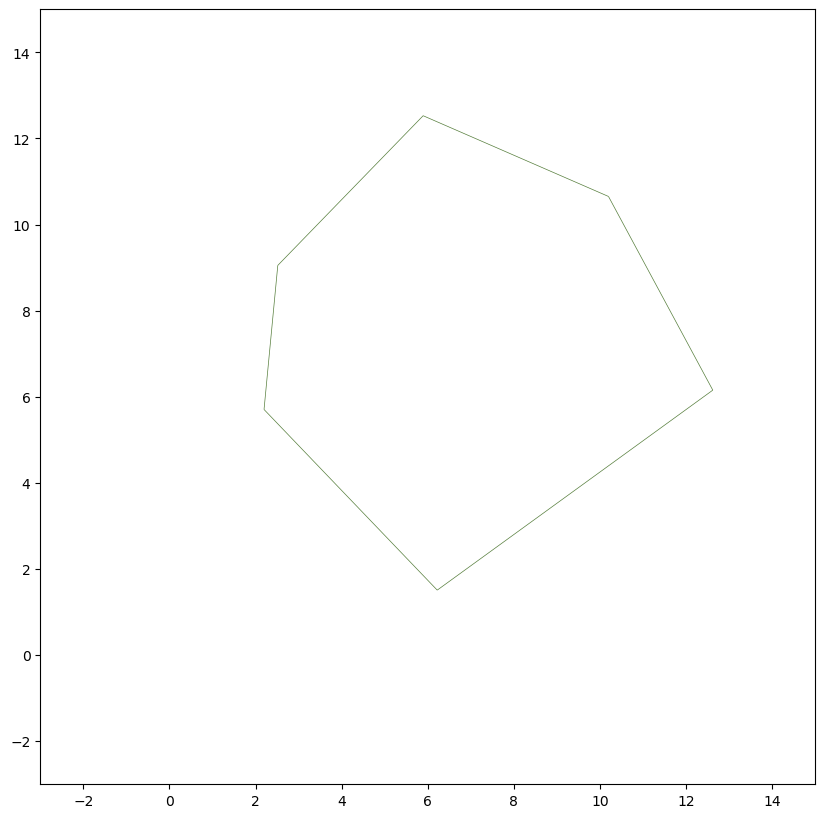

In [196]:
res = solver.find_energy_min(model_sheet_new, geom, area_model)

print("Successfull gradient descent? ", res['success'])
fig, ax = sheet_view(model_sheet_new)

fig.set_size_inches(10, 12)
ax.set_xlim(-3, 15)
ax.set_ylim(-3, 15)

ax.set_aspect('equal')

Boolean for the convergence success: 
True
Number of function evaluations: 
8
Information on the convergence: 
CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH


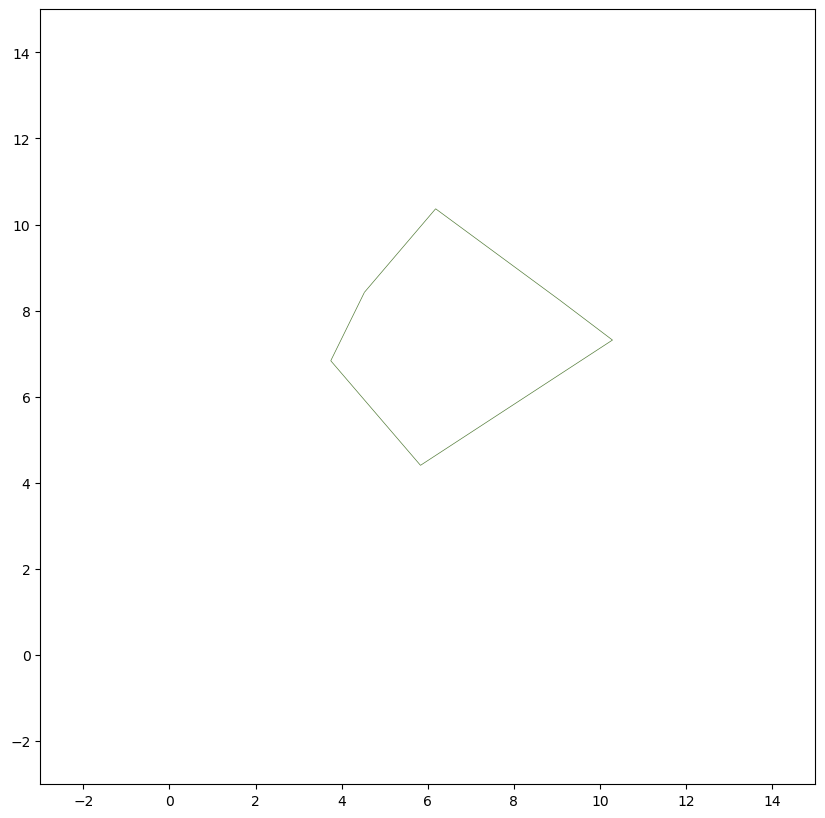

In [160]:
model_sheet_new.face_df.loc[0, "prefered_area"] = 20.0

res = solver.find_energy_min(model_sheet_new, geom, area_model, options={"ftol": 1e-2})


fig, ax = sheet_view(model_sheet_new)

fig.set_size_inches(10, 12)
ax.set_xlim(-3, 15)
ax.set_ylim(-3, 15)


ax.set_aspect('equal')
print("Boolean for the convergence success: ")
print(res.success)

print("Number of function evaluations: ")

print(res.nfev) 

print("Information on the convergence: ")
print(res.message)

In [162]:
pprint(vars(model_sheet_new), sort_dicts=False, width=70)

{'_backups': deque([], maxlen=5),
 'identifier': '1f_copy_copy',
 'datasets': {'face':              x    y    z  num_sides       area  perimeter  is_alive  id  \
face                                                                      
0     6.608333  7.6  0.0          6  20.000559  17.960658         1   0   

      height  rho        vol  area_elasticity  prefered_area  
face                                                          
0       -4.0  0.0 -80.002237              1.0           20.0  ,
              'vert':               x          y    z  is_active  rho  height  basal_shift       gx  \
vert                                                                            
0      4.530069   8.426745  0.0          1  0.0    -4.0          4.0 -1.12788   
1      6.183587  10.366480  0.0          1  0.0    -4.0          4.0 -0.36873   
2      9.065483   8.244597  0.0          1  0.0    -4.0          4.0  0.73746   
3     10.290777   7.317427  0.0          1  0.0    -4.0          4.0  

In [164]:
print('Total gradient error: ')
solver.check_grad(model_sheet_new, geom, area_model)

Total gradient error: 


0.0020254641104465033

In [166]:
app_grad = solver.approx_grad(model_sheet_new, geom, area_model)

In [168]:
app_grad = pd.DataFrame(app_grad.reshape((-1, 3)), columns=['gx', 'gy', 'gz'])

In [170]:
app_grad.head()


,gx,gy,gz
0,-0.000987,0.000681,0.0
1,0.000051,0.001268,0.0
2,0.000852,0.001148,0.0
3,0.001073,-0.000904,0.0
4,0.000134,-0.001829,0.0


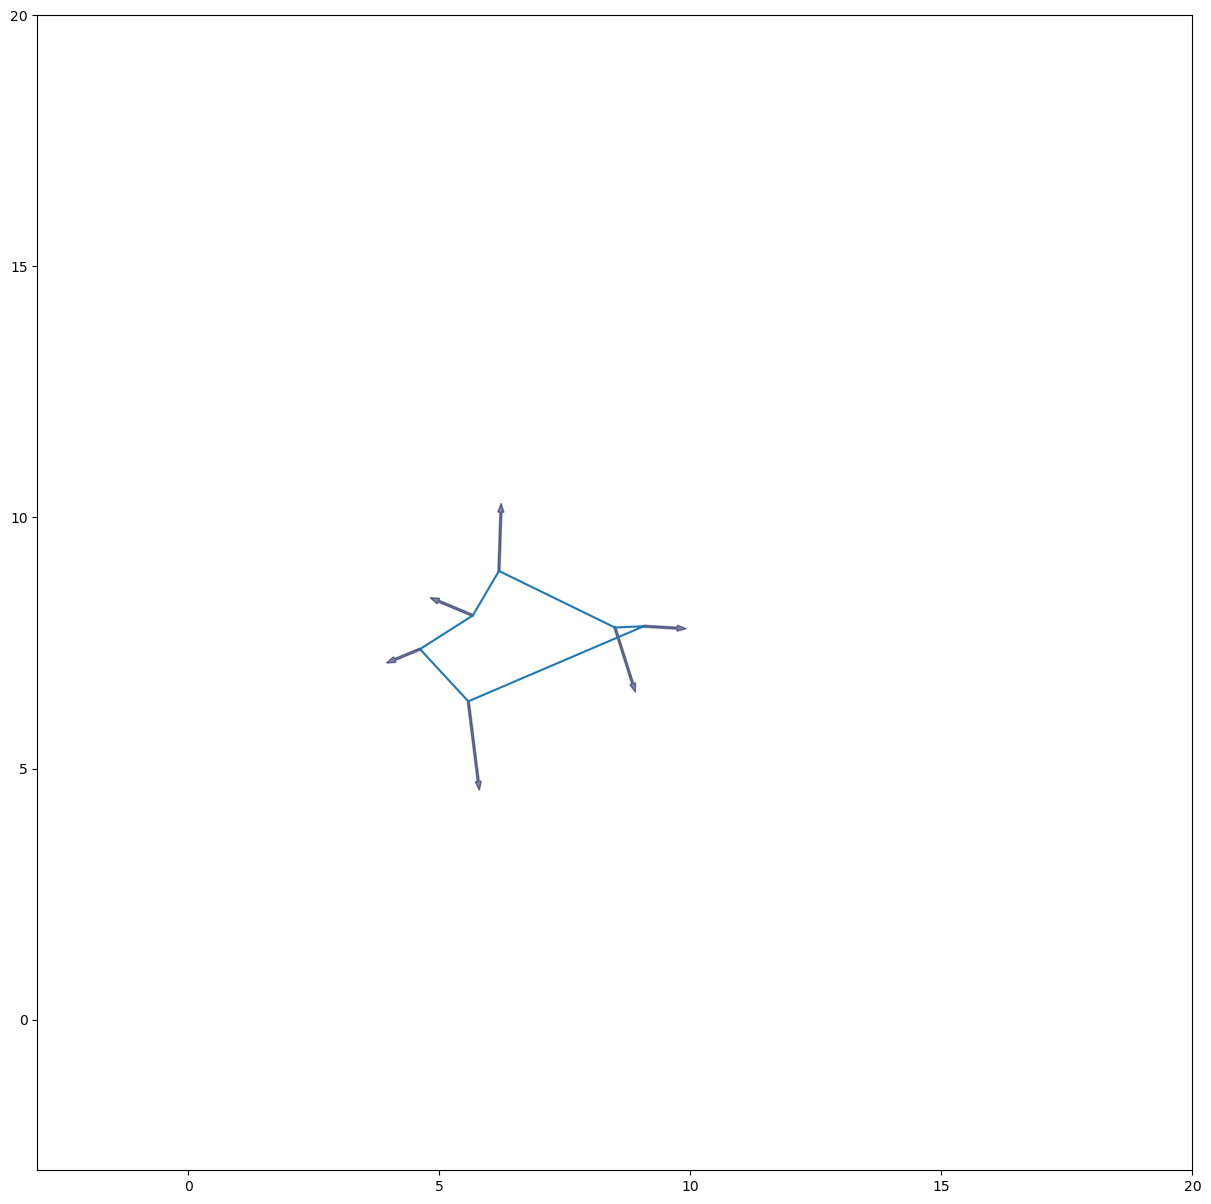

In [92]:
from tyssue import History
from tyssue.solvers.viscous import EulerSolver
from tyssue.draw.plt_draw import create_gif

geom.update_all(model_sheet_new)
# pprint(vars(model_sheet), sort_dicts=False, width=70)  # check the structure of the model_sheet
# model_sheet.settings['threshold_length'] = 1e-3

model_sheet_new.update_specs(config.dynamics.quasistatic_plane_spec())
model_sheet_new.face_df["prefered_area"] = model_sheet_new.face_df["area"].mean()
history = History(model_sheet_new) #, extra_cols={"edge":["dx", "dy", "sx", "sy", "tx", "ty"]})

# model_sheet.vert_df['viscosity'] = 1.0
# model_sheetmodel_sheet.edge_df.loc[[0, 17],  'line_tension'] *= 4
model_sheet_new.face_df.loc[0,  'prefered_area'] = 60.0

fig, ax = plot_forces(model_sheet_new, geom, area_model, ['x', 'y'], scaling=0.009)


ax.set_xlim(-3, 20)
ax.set_ylim(-3, 20)
fig.set_size_inches(15, 15)

In [52]:
solver = EulerSolver(
    model_sheet_new,
    geom,
    area_model,
    history=history,
    auto_reconnect=True)


In [54]:
def on_topo_change(model_sheet_new):
    print('Topology changed!\n')
    model_sheet_new.area_df["prefered_area"] = model_sheet_new.specs["area"]["prefered_area"]

In [80]:
import warnings
warnings.filterwarnings("ignore")

model_sheet_new.vert_df["viscosity"] = 20.0
res = solver.solve(tf=500, dt=0.05, on_topo_change=on_topo_change,
                   topo_change_args=(solver.eptm,))

pprint(vars(model_sheet_new), sort_dicts=False, width=70)

{'_backups': deque([], maxlen=5),
 'identifier': '1f_copy_copy',
 'datasets': {'face':              x        y             z  num_sides  area  perimeter  is_alive  \
face                                                                          
0     6.604736  7.72353  3.163877e-09          6   5.0  10.637252         1   

      id  height           rho   vol  area_elasticity  prefered_area  \
face                                                                   
0      0    -4.0  3.163877e-09 -20.0              1.0            5.0   

      contractility  
face                 
0              0.04  ,
              'vert':              x         y             z  is_active           rho  height  \
vert                                                                      
0     5.669513  8.047903  3.398821e-09          1  3.398821e-09    -4.0   
1     6.189548  8.934440  1.667743e-09          1  1.667743e-09    -4.0   
2     8.498885  7.808170  1.455140e-09          1  1.455140e-09    -4

In [96]:
create_gif(solver.history, "sheet3.gif", num_frames=500)

'C:\\Users\\Aryan\\tyssue Simulations\\sheet3.gif'

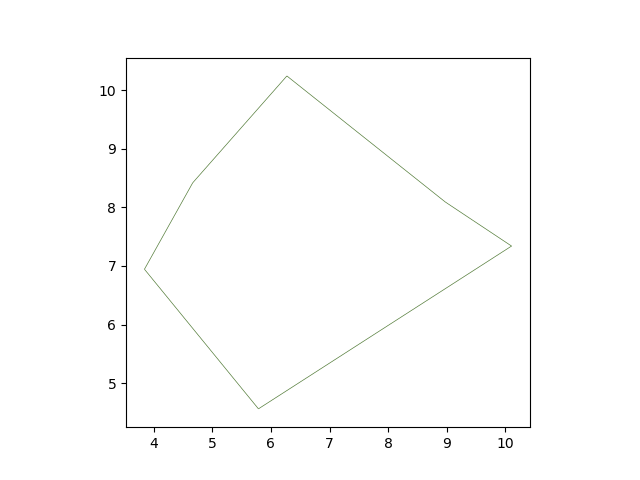

In [90]:
%matplotlib inline
from IPython.display import Image

Image("sheet3.gif")

In [9]:
import os

print("Current directory:", os.getcwd())
print("GIF exists:", os.path.exists("sheet3.gif"))
print("Files:", os.listdir())

Current directory: C:\Users\Aryan\tyssue Simulations
GIF exists: True
Files: ['.ipynb_checkpoints', 'Cell_growth.gif', 'division.gif', 'energy_landscape.png', 'frames', 'gradual_T1.gif', 'halfedge generation.ipynb', 'halfedge_native.png', 'halfedge_tricolor.png', 'hex_01_sanitized.png', 'hex_02_trimmed.png', 'intro.ipynb', 'Mesh Generation.ipynb', 'sheet2.gif', 'sheet3.gif', 'simple_growth.gif', 'tyssue1.ipynb', 'Untitled.ipynb', 'Untitled1.ipynb', 'voronoi_01_bounded.png', 'voronoi_02_relax_step1.png', 'voronoi_03_relax_step2.png', 'voronoi_04_relax_step3.png']


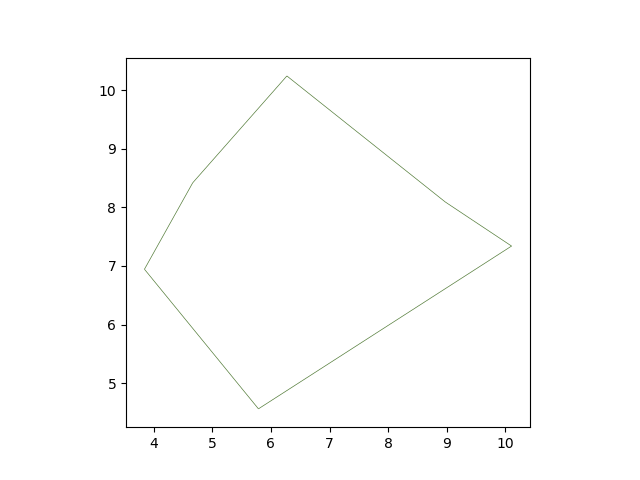

In [10]:
from IPython.display import Image, display
from pathlib import Path

gif_path = Path.cwd() / "sheet3.gif"

if gif_path.exists():
    display(Image(filename=str(gif_path)))
else:
    print(f"GIF not found at: {gif_path}")

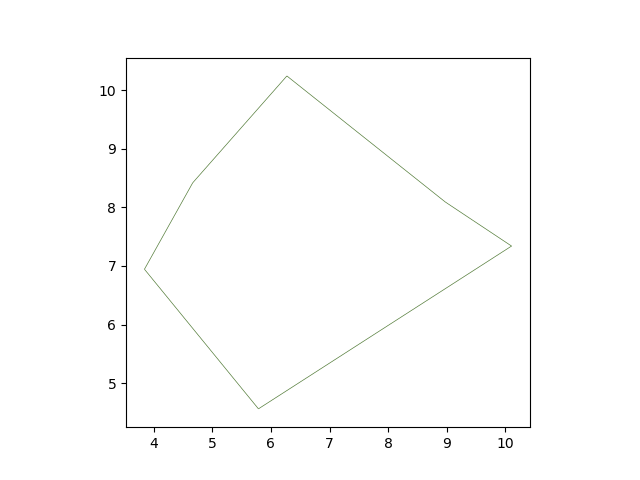

In [11]:
from pathlib import Path
from IPython.display import Image, display

output_path = Path.cwd() / "sheet3.gif"

# Generate the GIF using your existing Tyssue code.
# For example, if using the Tyssue History object:
# history.animate(output=str(output_path))  # Check your API/version

if output_path.exists():
    display(Image(filename=str(output_path)))
else:
    print("The GIF was not created. Check the GIF-generation step.")

In [78]:


import subprocess

result = subprocess.run(
    ["magick", "-version"],
    capture_output=True,
    text=True
)

print(result.stdout or result.stderr)

FileNotFoundError: [WinError 2] The system cannot find the file specified

In [80]:
import subprocess

subprocess.run(["convert", "-version"], check=True)

CalledProcessError: Command '['convert', '-version']' returned non-zero exit status 4.

In [82]:
import shutil

print("magick:", shutil.which("magick"))
print("convert:", shutil.which("convert"))

magick: None
convert: C:\windows\system32\convert.EXE


In [84]:
import subprocess

magick_path = r"C:\Program Files\ImageMagick-7.1.2-Q16-HDRI\magick.exe"

result = subprocess.run(
    [magick_path, "-version"],
    capture_output=True,
    text=True
)

print(result.stdout)

Version: ImageMagick 7.1.2-34 Q16-HDRI x64 a0c4bf7:20261014 https://imagemagick.org
Copyright: (C) 1999 ImageMagick Studio LLC
License: https://imagemagick.org/license/
Features: Channel-masks(64-bit) Cipher DPC HDRI Modules OpenCL OpenMP(2.0) 
Delegates (built-in): bzlib cairo freetype gslib heic jng jp2 jpeg jxl lcms lqr lzma openexr pangocairo png ps raqm raw rsvg tiff webp xml zip zlib zstd
Compiler: Visual Studio 2026 (195136260)



In [86]:
import os

imagemagick_dir = r"C:\Program Files\ImageMagick-7.1.2-Q16-HDRI"

os.environ["PATH"] = imagemagick_dir + os.pathsep + os.environ["PATH"]

In [88]:
import shutil

print(shutil.which("magick"))

C:\Program Files\ImageMagick-7.1.2-Q16-HDRI\magick.EXE


In [92]:
from pathlib import Path

print("Working directory:", Path.cwd())
print("GIF exists:", Path("sheet3.gif").exists())

Working directory: C:\Users\Aryan\tyssue Simulations
GIF exists: False


In [94]:
from IPython.display import Image, display

display(Image(filename=str(Path("sheet3.gif").resolve())))

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Aryan\\tyssue Simulations\\sheet3.gif'